# 07 · `cli.py`: the `nextbrain-utils` command and a full pipeline

`cli.py` defines one `argparse` sub-command per module. Each one is a thin
wrapper that **broadcasts** its file lists and calls the Python function in a
loop:

* 0 outputs → `save=True` (automatic naming next to the input)
* 1 output → reused for every input. *Careful: with several inputs, each one
  overwrites the previous output.*
* N outputs → paired with the N inputs (otherwise `ValueError`)

| sub-command | Python function | key options |
|---|---|---|
| `combine` | `combine_hemis` | `-l`, `-r`, `-o`, `-m` |
| `allen` | `to_allen` | `-c {gyr,dev,dk}`, `-s16` |
| `simplify` | `simplify` | `-l LABELS…`, `-d` (hide missing), `-s16` |
| `aseg` / `supersynth` | `to_aseg` / `to_supersynth` | `-s SIDE|mask`, `-c` (claustrum) |
| `laura` | `to_laura` | `-s SIDE|mask` |
| `lut` | `allen_lut` or copy of a bundled LUT | `-l {allen,allen+dk,nextbrain,aseg,freesurfer,supersynth*,laura}`, `-a`, `-s16` |

In [1]:
import sys, os
from pathlib import Path
sys.path.insert(0, ".")          # nb_helpers.py lives next to the notebooks
WORK = Path("_work/07"); WORK.mkdir(parents=True, exist_ok=True)   # scratch outputs of this notebook

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import nb_helpers as H
pd.set_option("display.max_rows", 60, "display.max_colwidth", 70)

In [2]:
import subprocess, shutil
EXE = shutil.which("nextbrain-utils")
print("executable:", EXE)

def run(*args, cwd=WORK):
    p = subprocess.run([EXE, *map(str, args)], cwd=cwd, capture_output=True, text=True)
    print("$ nextbrain-utils", " ".join(map(str, args)), f"   [exit {p.returncode}]")
    out = (p.stdout + p.stderr).strip()
    if out:
        print(out if len(out) < 1500 else out[:700] + "\n  [...]\n" + out[-700:])
    return p.returncode

run("-h")

executable: /home/agustin/miniconda3/envs/nxb/bin/nextbrain-utils


$ nextbrain-utils -h    [exit 0]
usage: nextbrain-utils [-h]
                       {combine,allen,aseg,supersynth,laura,simplify,lut} ...

positional arguments:
  {combine,allen,aseg,supersynth,laura,simplify,lut}
    combine             Combine two NextBrain hemispheres into a single file.
    allen               Convert NextBrain labels to Allen Brain labels.
    aseg                Convert NextBrain labels to ASeg+AParc labels.
    supersynth          Convert NextBrain labels to SuperSynth labels.
    laura               Convert NextBrain labels to Laura's labels.
    simplify            Simplify Allen Brain label maps.
    lut                 Write freesurfer lookup tables.

options:
  -h, --help            show this help message and exit


0

In [3]:
run("allen", "-h")      # the long help text is RawDescriptionHelpFormatter -> the DK tables print verbatim

$ nextbrain-utils allen -h    [exit 0]
usage: nextbrain-utils allen [-h] [-i INPUT [INPUT ...]]
                             [-o OUTPUT [OUTPUT ...]] [-c {gyr,dev,dk}] [-s16]

Convert NextBrain labels to Allen Brain labels.

NextBrain does not use the Allen ontology for its cortical labels, but
instead uses the Desikan-Killiany labels (i.e., Freesurfer's "aparc").

We implement three different ways to deal with them. They can be
selected using the `--cortex-ontology` option.

1) dk = Freesurfer's Desikan-Killiany labels
--------------------------------------------

This option preserves the Desikan-Killiany labels and their IDs (which
happen to not be used by any region in the Allen
  [...]


options:
  -h, --help            show this help message and exit
  -i INPUT [INPUT ...], --input INPUT [INPUT ...]
                        Input segmentation(s).
  -o OUTPUT [OUTPUT ...], --output OUTPUT [OUTPUT ...]
                        Output filename(s) of the segmentation(s).
  -c {gyr,dev,

0

## Full pipeline on the phantom

In [4]:
for f in WORK.glob("*.nii.gz"):
    f.unlink()
nib.save(H.make_phantom_hemi("L"), WORK / "seg.left.nii.gz")
nib.save(H.make_phantom_hemi("R"), WORK / "seg.right.nii.gz")

run("combine", "-l", "seg.left.nii.gz", "-r", "seg.right.nii.gz",
    "-o", "seg.both.nii.gz", "-m", "sides.nii.gz")

$ nextbrain-utils combine -l seg.left.nii.gz -r seg.right.nii.gz -o seg.both.nii.gz -m sides.nii.gz    [exit 0]


0

In [5]:
# Default cortex ontology (gyr) -> bug 1 (KeyError), and so does dev
run("allen", "-i", "seg.both.nii.gz", "-o", "seg.allen.nii.gz")

$ nextbrain-utils allen -i seg.both.nii.gz -o seg.allen.nii.gz    [exit 1]
Traceback (most recent call last):
  File "/home/agustin/miniconda3/envs/nxb/bin/nextbrain-utils", line 6, in <module>
    sys.exit(main())
             ^^^^^^
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/cli.py", line 575, in main
    args.func(args)
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/cli.py", line 90, in _to_allen
    to_allen(inp, args.cortex_ontology, args.compat_16bits, out)
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/to_allen.py", line 73, in to_allen
    nextbrain2allen = get_nextbrain2allen_map(ontology)
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/to_allen.py", line 179, in get_nextbrain2al

1

In [6]:
# DK cortex works; -s16 for Freeview
run("allen", "-i", "seg.both.nii.gz", "-o", "seg.allen.nii.gz", "-c", "dk", "-s16")
run("simplify", "-i", "seg.allen.nii.gz", "-o", "seg.simple.nii.gz", "-s16",
    "-l", *"AMY ATA EXA Ca Pu NAC GP Cla BF THM SubTH HTH HIP".split())
run("aseg",       "-i", "seg.both.nii.gz", "-o", "seg.aseg.nii.gz",       "-s", "sides.nii.gz")
run("supersynth", "-i", "seg.both.nii.gz", "-o", "seg.supersynth.nii.gz", "-s", "sides.nii.gz", "-c")  # issue 13 -> IndexError
run("supersynth", "-i", "seg.both.nii.gz", "-o", "seg.supersynth.nii.gz", "-s", "sides.nii.gz")
run("laura",      "-i", "seg.both.nii.gz", "-o", "seg.laura.nii.gz",      "-s", "sides.nii.gz")
for lut in ["allen+dk", "aseg", "supersynth", "laura"]:
    run("lut", "-l", lut, "-s16", "-o", f"{lut}.lut.txt")
print(sorted(p.name for p in WORK.iterdir() if p.suffix in (".gz", ".txt")))

$ nextbrain-utils allen -i seg.both.nii.gz -o seg.allen.nii.gz -c dk -s16    [exit 0]


$ nextbrain-utils simplify -i seg.allen.nii.gz -o seg.simple.nii.gz -s16 -l AMY ATA EXA Ca Pu NAC GP Cla BF THM SubTH HTH HIP    [exit 0]


$ nextbrain-utils aseg -i seg.both.nii.gz -o seg.aseg.nii.gz -s sides.nii.gz    [exit 0]


$ nextbrain-utils supersynth -i seg.both.nii.gz -o seg.supersynth.nii.gz -s sides.nii.gz -c    [exit 1]
Traceback (most recent call last):
  File "/home/agustin/miniconda3/envs/nxb/bin/nextbrain-utils", line 6, in <module>
    sys.exit(main())
             ^^^^^^
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/cli.py", line 575, in main
    args.func(args)
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/cli.py", line 362, in _to_supersynth
    to_supersynth(inp, side, args.claustrum, out)
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_utils/to_supersynth.py", line 73, in to_supersynth
    mapping_left = get_nextbrain2supersynth_map("L", claustrum)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/allen_ontology/nextbrain-utils/nextbrain_uti

$ nextbrain-utils supersynth -i seg.both.nii.gz -o seg.supersynth.nii.gz -s sides.nii.gz    [exit 0]


$ nextbrain-utils laura -i seg.both.nii.gz -o seg.laura.nii.gz -s sides.nii.gz    [exit 0]


$ nextbrain-utils lut -l allen+dk -s16 -o allen+dk.lut.txt    [exit 0]
$ nextbrain-utils lut -l aseg -s16 -o aseg.lut.txt    [exit 0]


$ nextbrain-utils lut -l supersynth -s16 -o supersynth.lut.txt    [exit 0]
$ nextbrain-utils lut -l laura -s16 -o laura.lut.txt    [exit 0]
['allen+dk.lut.txt', 'aseg.lut.txt', 'laura.lut.txt', 'seg.allen.nii.gz', 'seg.aseg.nii.gz', 'seg.both.nii.gz', 'seg.laura.nii.gz', 'seg.left.nii.gz', 'seg.right.nii.gz', 'seg.simple.nii.gz', 'seg.supersynth.nii.gz', 'sides.nii.gz', 'supersynth.lut.txt']


rows in allen+dk.lut.txt: 3317 | DK rows (2000-2035): 0  <- bug 2


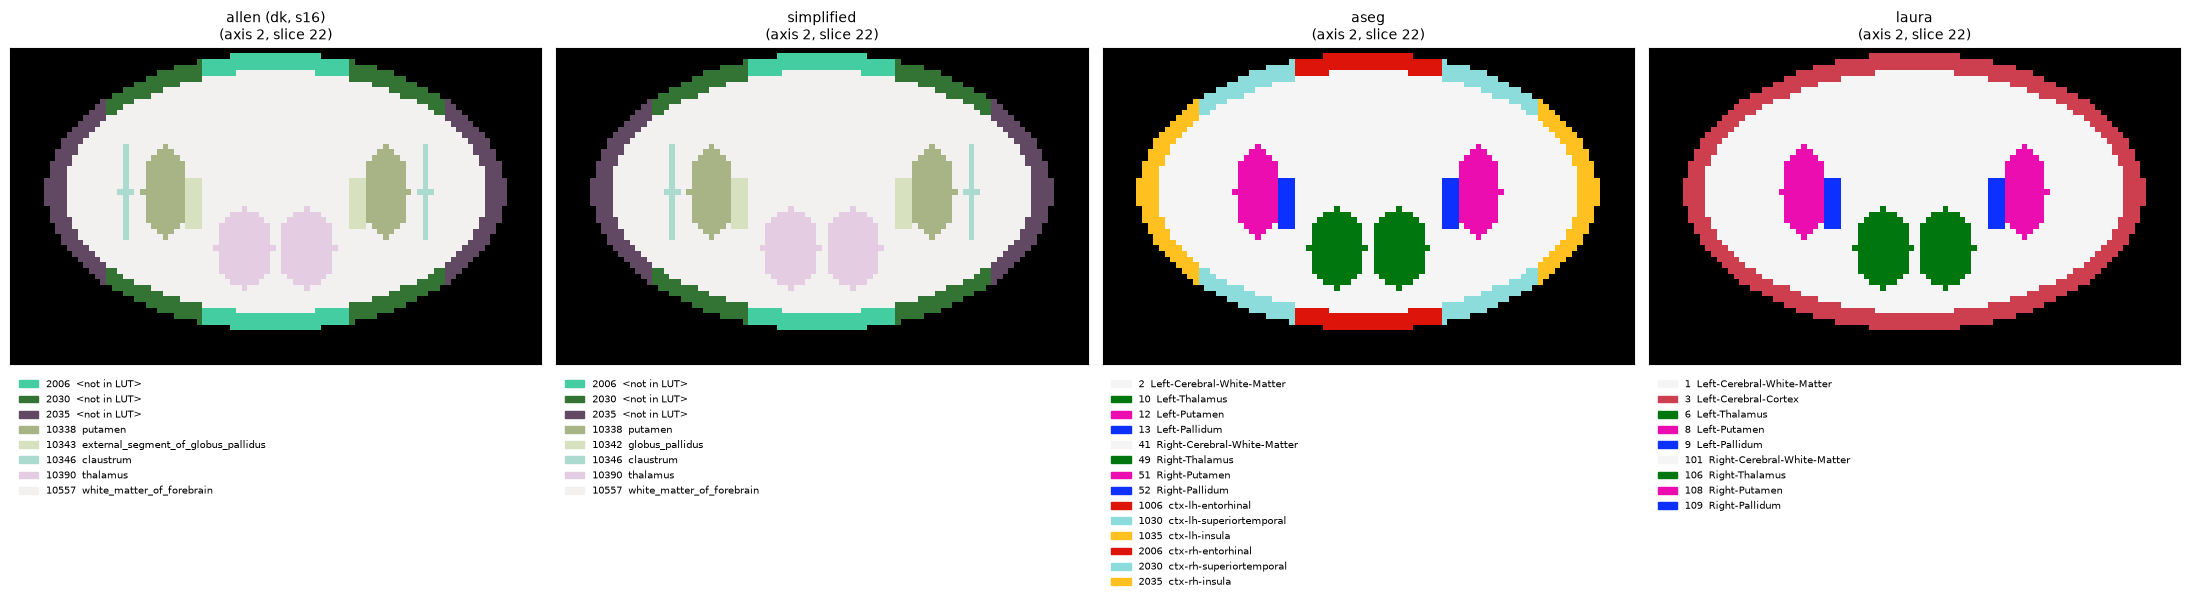

In [7]:
from nextbrain_utils.io import load_lut
L = {n: load_lut(WORK / f"{n}.lut.txt") for n in ["allen+dk", "aseg", "supersynth", "laura"]}
print("rows in allen+dk.lut.txt:", len(L["allen+dk"]), "| DK rows (2000-2035):", int(((L["allen+dk"]["ID"] >= 2000) & (L["allen+dk"]["ID"] <= 2035)).sum()), " <- bug 2")
imgs = [nib.load(WORK / f) for f in ["seg.allen.nii.gz", "seg.simple.nii.gz", "seg.aseg.nii.gz", "seg.laura.nii.gz"]]
H.show_seg(imgs, [L["allen+dk"], L["allen+dk"], L["aseg"], L["laura"]], axis=2, index=22,
           titles=["allen (dk, s16)", "simplified", "aseg", "laura"], figsize=(22, 7.5))

Viewing in Freeview (outside the notebook):

```bash
cd notebooks/_work/07
freeview -v seg.allen.nii.gz:colormap=lut:lut=allen+dk.lut.txt \
         seg.aseg.nii.gz:colormap=lut:lut=aseg.lut.txt
```

## ⚠️ Issue 8: `python -m nextbrain_utils`

The package ships `__main__,py` (with a comma), so Python finds no
`__main__.py`:

In [8]:
p = subprocess.run([sys.executable, "-m", "nextbrain_utils", "-h"], capture_output=True, text=True)
print(p.returncode, p.stderr.strip().splitlines()[-1])

1 /home/agustin/miniconda3/envs/nxb/bin/python: No module named nextbrain_utils.__main__; 'nextbrain_utils' is a package and cannot be directly executed


## Summary

* Use `combine` first. Keep the **sides mask**: it is the only record of
  which hemisphere each voxel belongs to, since NextBrain uses the right-side
  DK IDs everywhere.
* `allen` maps subcortex by **name** (29 labels have no match and keep their
  NextBrain ID) and maps cortex with one of three DK tables. Only `-c dk`
  works with the current LUT, until bug 1 is fixed. `-s16` overflows label 594.
* `simplify` collapses Allen subtrees. The topmost listed node wins. It needs
  about 2 GiB of RAM.
* `aseg`/`supersynth`/`laura` are YAML-driven and lateralised by the sides mask
  (pass it as a path). Unlisted labels pass through unchanged. Laura's right
  cortex is currently mislabelled, and `supersynth -c` crashes.
* `lut` writes Freeview tables. `allen+dk` currently lacks the DK rows.